# Synthetic correlation-target ensemble

Can a label-free target derived from channel relationships create useful disagreement?

Read top-to-bottom: setup → equations → architecture → training → figures → LOTO → interpretation.
**Safe default:** saved-result exploration only; training is disabled.

In [1]:
from pathlib import Path
import sys
ROOT = next((p for p in (Path.cwd(), *Path.cwd().parents)
             if (p / 'ml/sci_rob/vanilla/registry.py').exists()), None)
if ROOT is None:
    raise RuntimeError('Launch Jupyter within this repository.')
sys.path.insert(0, str(ROOT / 'notebooks/sci_rob/model_exploration'))
get_ipython().run_line_magic('matplotlib', 'inline')
from _exploration import *
import torch
from dataclasses import asdict
torch.set_num_threads(2)  # small architecture checks; training CLI runs separately
torch.manual_seed(0)
RUN_TRAINING = False
print('Repository:', ROOT)
print('Kernel:', sys.executable)

Repository: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton
Kernel: /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python


In [2]:
KEY = 'synthetic'
RUN = ROOT / RUNS[KEY]
inventory(RUN)

**Artifact directory:** `ml/sci_rob/vanilla/runs/synthetic`

,artifact,available
0,report.json,True
1,final.pt,True
2,eval_test.json,True
3,figures,True


## Data and evaluation contract

- Input: **16 channels × 200 samples**, one second at 200 Hz; stored window stride 10 samples.
- Original ID tasks: level ground (LG), ramp ascent (RA), ramp descent (RD).
  Original pseudo-OOD tasks: stair ascent (SA), stair descent (SD), standing (ST), transitions (TR).
- Participants: 12 train / 4 validation / 4 test. Task availability differs by participant.
  Input scaling is fitted on training data, never refitted on test data.
- Scoring does **not** predict a task label. High $\Psi$ means more anomalous.

$$\widetilde\Psi_t=\operatorname{median}(\Psi_{t-9},\ldots,\Psi_t),\qquad
\tau=Q_{0.995}(\widetilde\Psi_{\mathrm{train,ID}}),\qquad
\widehat o_t=\mathbf1[\widetilde\Psi_t>\tau].$$

Filtering restarts for each trial; early windows use the available history. The ten-score
filter corresponds to the repository's nominal 0.5 s smoothing setting, **not** ten raw samples.

$$\mathrm{recall}=\frac{TP}{TP+FN},\quad
\mathrm{specificity}=\frac{TN}{TN+FP},\quad J=\mathrm{recall}+\mathrm{specificity}-1.$$

AUROC measures ranking across thresholds; it is **not the fraction of OOD detected**.
OOD is the positive class. Tables below show J on −1 to 1, although source JSON stores 100J.
Scores and thresholds are not calibrated probabilities of being unsafe.

## Model and mathematics

For 16 channels, sum all 120 distinct pairs within each standardized window:
 $$s(x)=\sum_{i<j}\frac{\operatorname{cov}(x_i,x_j)}
 {\max(\operatorname{sd}(x_i),0.01)\max(\operatorname{sd}(x_j),0.01)},\qquad
 y=\frac{s-\mu_{s,\mathrm{train}}}{\sigma_{s,\mathrm{train}}}.$$
 The SD floor suppresses unstable correlations in near-constant windows. Ordinary Pearson
 correlation is scale-invariant; the fixed floor can break exact invariance near that floor.
 The target is computed from the **same observed window**, not a future measurement.
 Seven TCNs use the gait-phase trunk but have **one linear output** ($D=1$); all target masks are valid.

For branch $m$ and target dimension $d$, train with masked mean squared error:

$$\mathcal L=\frac{\sum_{n,m,d}a_{nd}(f_{md}(x_n)-y_{nd})^2}
{M\sum_{n,d}a_{nd}},\qquad M=7.$$

$a$ is the target-validity mask. The online score uses no target labels:

$$\bar f_d(x)=\frac1M\sum_m f_{md}(x),\qquad
\Psi(x)=\frac1D\sum_d\frac1M\sum_m(f_{md}(x)-\bar f_d(x))^2.$$

This is population variance across branches, not sample variance. Agreement is a candidate
uncertainty signal, **not a guarantee that an input is familiar or a prediction is correct**.

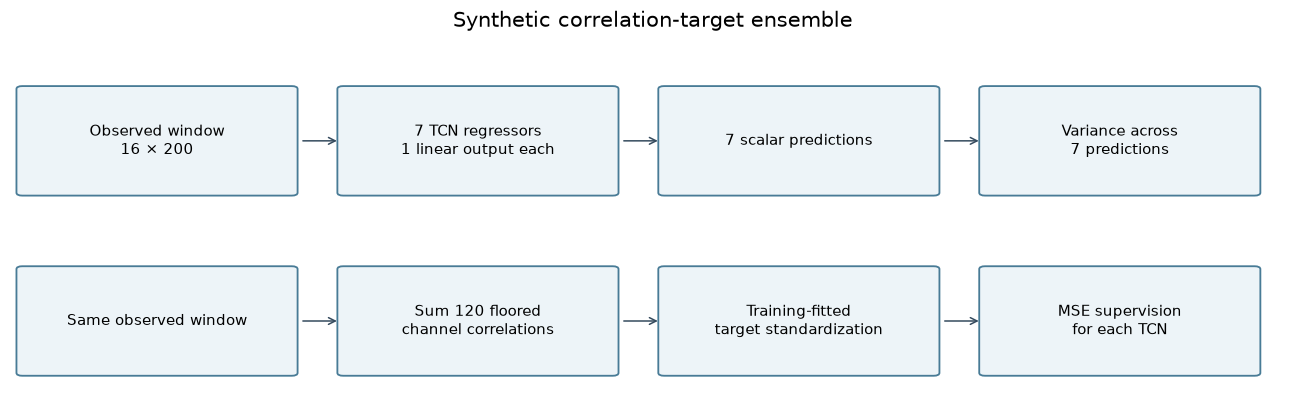

In [3]:
diagram([['Observed window\n16 × 200', '7 TCN regressors\n1 linear output each', '7 scalar predictions', 'Variance across\n7 predictions'], ['Same observed window', 'Sum 120 floored\nchannel correlations', 'Training-fitted\ntarget standardization', 'MSE supervision\nfor each TCN']], 'Synthetic correlation-target ensemble')

### Executable architecture check

This constructs **fresh random weights** and checks shapes only. The saved figures later come from trained runs; this dummy forward pass does not.

In [4]:
from models.ensemble import create_ensemble
model = create_ensemble(16, 1, activation='linear')
example = torch.zeros(2, 16, 200)
output = model_shapes(model, example)

GaitPhaseEnsemble: 321,307 parameters
Input: (2, 16, 200)   Outputs: [(2, 7, 1)]
Layer table shows one representative branch; weights are not shared.


,module,class,direct parameters
0,network.0.conv,CausalConv1d,9630
1,network.0.norm,BatchNorm1d,60
2,network.0.relu,ReLU,0
3,network.1.conv,CausalConv1d,18030
4,network.1.norm,BatchNorm1d,60
5,network.1.relu,ReLU,0
6,network.2.conv,CausalConv1d,18030
7,network.2.norm,BatchNorm1d,60
8,network.2.relu,ReLU,0
9,fc,Linear,31


## Training


Twelve leave-one-subject-out (LOSO) folds over the training participants select the final
epoch count from held-out-subject loss. A freshly initialized ensemble then trains on all
training participants for that duration. Defaults: Adam, learning rate 0.001, batch 1024,
maximum 60 fold epochs, patience 10. The report below is authoritative for a saved run.
Branches have independent weights/initialization but see the same training batches.
 The correlation target is standardized with training statistics; do not recompute that scaling on test participants.

In [5]:
from registry import get
config_class = get(KEY).config()
display(pd.Series(asdict(config_class()), name='current default').to_frame())

,current default
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,ml/sci_rob/vanilla/runs/synthetic
loso_folds,None


### Saved training configuration and learning curves

Current defaults can differ from a past run. Below we read the report; missing reports remain explicitly missing. Loss scales from different objectives are not directly comparable.

,saved value
lr,0.001
batch_size,1024
max_epochs,60
patience,10
seed,0
device,None
threshold_percentile,99.5
n_members,7
out_dir,/Users/dariussattari/Documents/thesis/Uncertai...
loso_folds,None


,saved result
target,correlation
horizon,40
threshold,0.033291
val_loss,0.086177
LOSO selected epochs,24


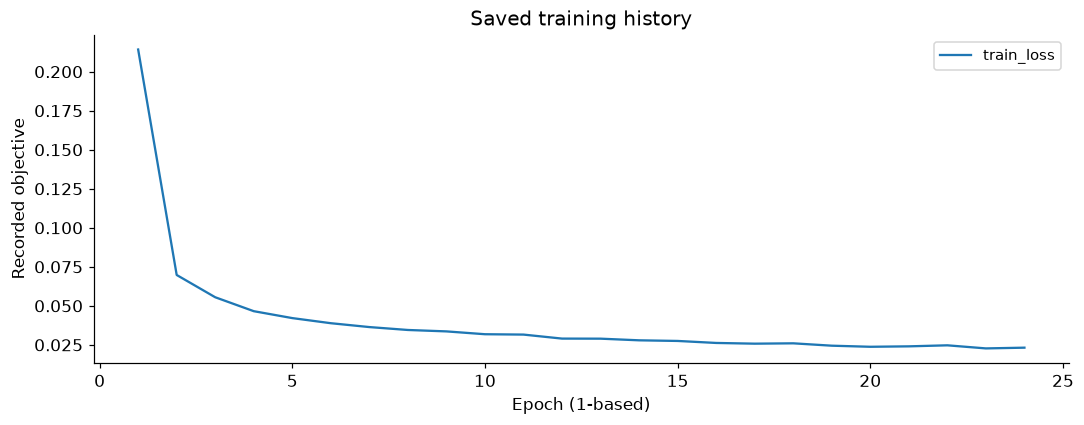

,epoch,train_loss,seconds
19,19,0.023731,115.7
20,20,0.024009,116.0
21,21,0.024667,115.4
22,22,0.022690,115.2
23,23,0.023160,107.8


**LOSO summary (epoch selection, not LOTO):**

{'n_epochs': 24,
 'folds': [{'subject': 'AB15',
   'best_epoch': 4,
   'val_loss': 0.11795723897737183,
   'epochs_run': 15},
  {'subject': 'AB17',
   'best_epoch': 40,
   'val_loss': 0.043923381821694946,
   'epochs_run': 51},
  {'subject': 'AB18',
   'best_epoch': 12,
   'val_loss': 0.09291794480443283,
   'epochs_run': 23},
  {'subject': 'AB19',
   'best_epoch': 7,
   'val_loss': 0.06142094293491164,
   'epochs_run': 18},
  {'subject': 'AB21',
   'best_epoch': 43,
   'val_loss': 0.03701972635550575,
   'epochs_run': 54},
  {'subject': 'AB23',
   'best_epoch': 42,
   'val_loss': 0.04358719931037846,
   'epochs_run': 53},
  {'subject': 'AB25',
   'best_epoch': 39,
   'val_loss': 0.09565745798182668,
   'epochs_run': 50},
  {'subject': 'AB26',
   'best_epoch': 16,
   'val_loss': 0.05443808801968537,
   'epochs_run': 27},
  {'subject': 'AB27',
   'best_epoch': 25,
   'val_loss': 0.06059689062179333,
   'epochs_run': 36},
  {'subject': 'AB28',
   'best_epoch': 19,
   'val_loss': 0.078207

In [6]:
config_and_history(RUN)

### Optional: run the real training pipeline

This can take hours. The commands use this kernel’s Python and write to a **new** directory. Set `RUN_TRAINING=True` in the setup cell only when ready. Existing runs are protected. After completion, set `RUN = NEW_RUN` and rerun the result cells.

In [7]:
NEW_RUN = ROOT / 'notebooks/sci_rob/model_exploration/runs' / KEY
commands = training_commands(KEY, NEW_RUN)
run_commands(commands, NEW_RUN, enabled=RUN_TRAINING)

/Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/.venv/bin/python /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/ml/sci_rob/vanilla/main.py all --model synthetic --out /Users/dariussattari/Documents/thesis/Uncertainty-Aware-Hip-Exoskeleton/notebooks/sci_rob/model_exploration/runs/synthetic

Preview only. Set RUN_TRAINING=True explicitly to run.


## Saved test results

These values come directly from `eval_test.json`. An optimized test-ROC threshold, where reported, is diagnostic—not a validated operating point.

In [8]:
results_table(RUN)

,AUROC,recall (%),specificity (%),J (−1 to 1),threshold
score,,,,,
primary,0.8126,42.4164,92.6997,0.3512,0.0333


,mode,kind,windows,flagged_%,median_psi
0,LG,ID,28668,6.1602,0.0137
1,RA,ID,18504,1.8158,0.0126
2,RD,ID,14784,16.3758,0.0185
3,SA,OOD,10273,18.6119,0.0221
4,SD,OOD,10155,60.5121,0.0377
5,ST,OOD,621,100.0000,0.3882
6,TR,OOD,1994,54.9649,0.0429


## Model behavior through figures

Images are embedded from the existing run, without rewriting it. Captions explain what each figure can and cannot establish.

**psi_by_task.png** — Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.

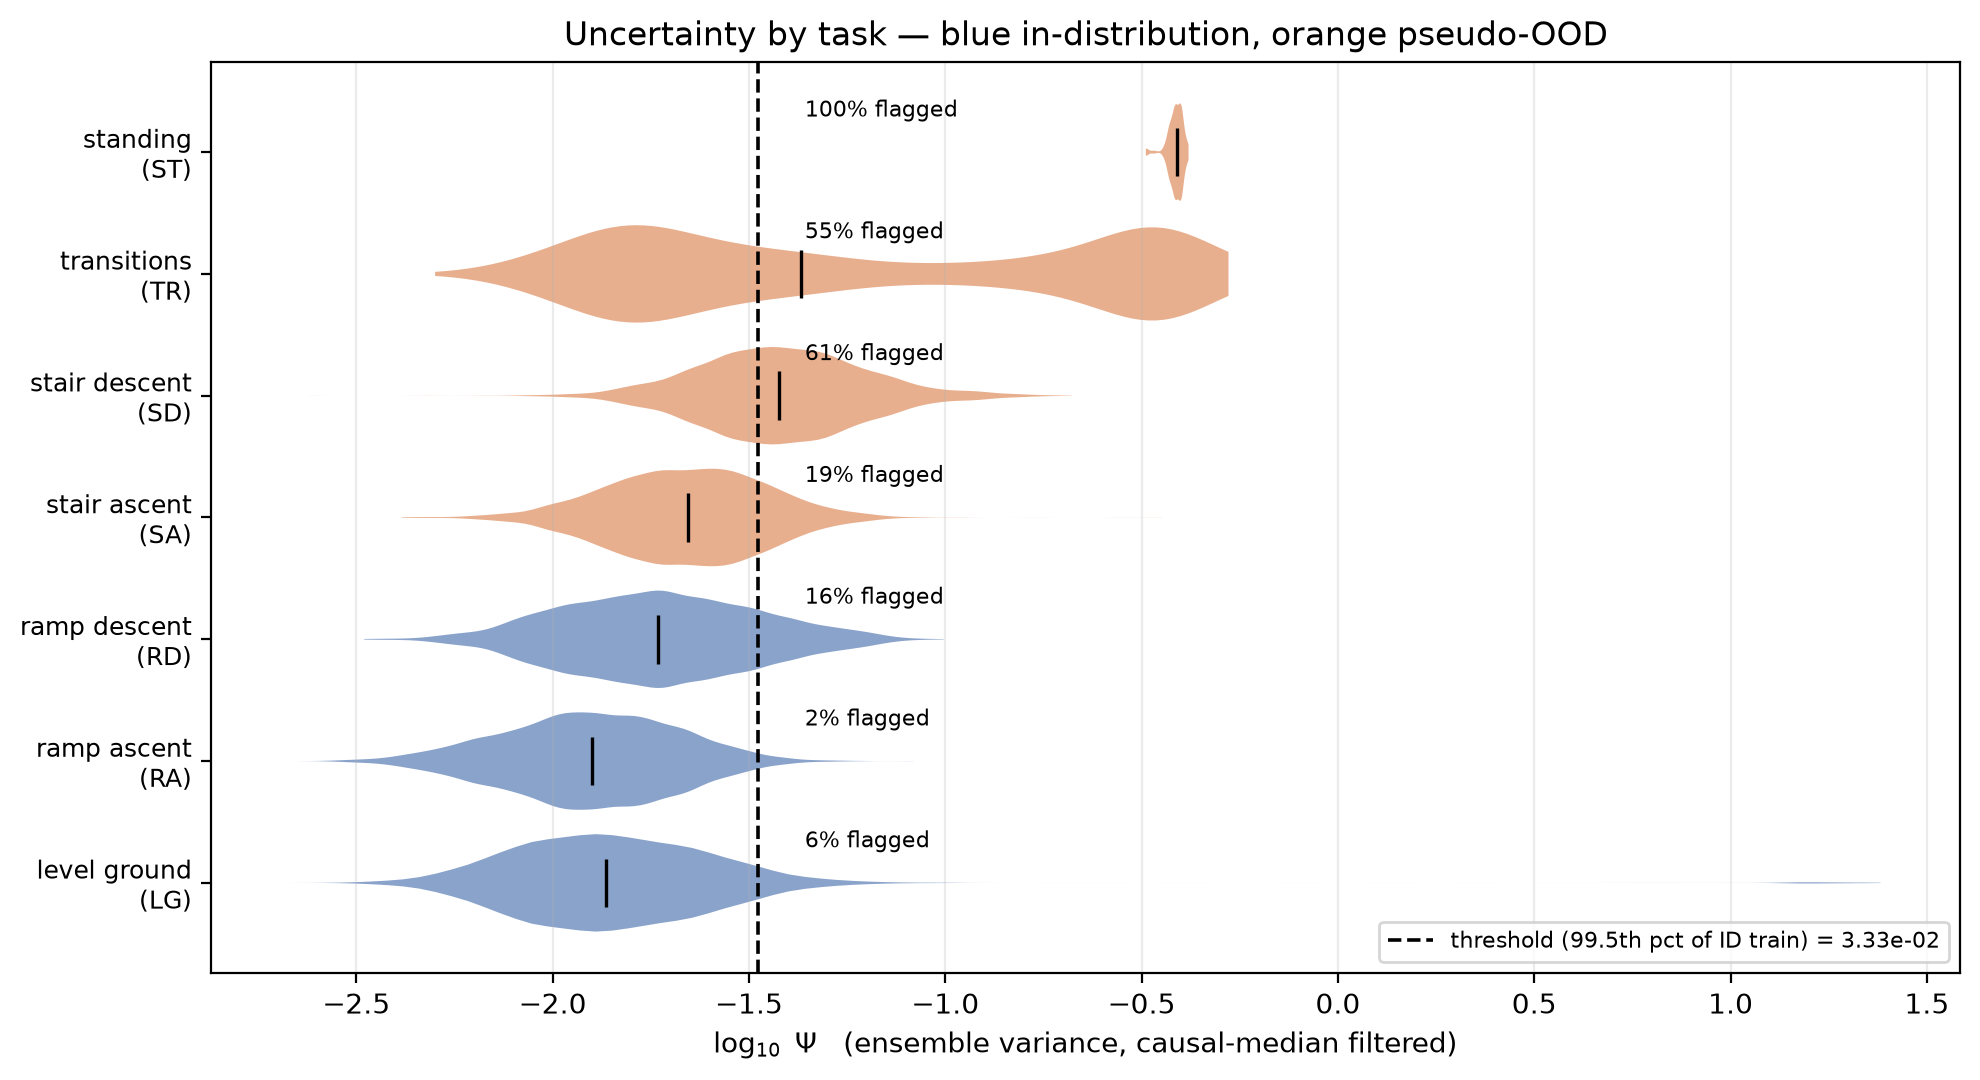

**roc.png** — Threshold sweep: ranking quality, not the fraction detected at the saved threshold.

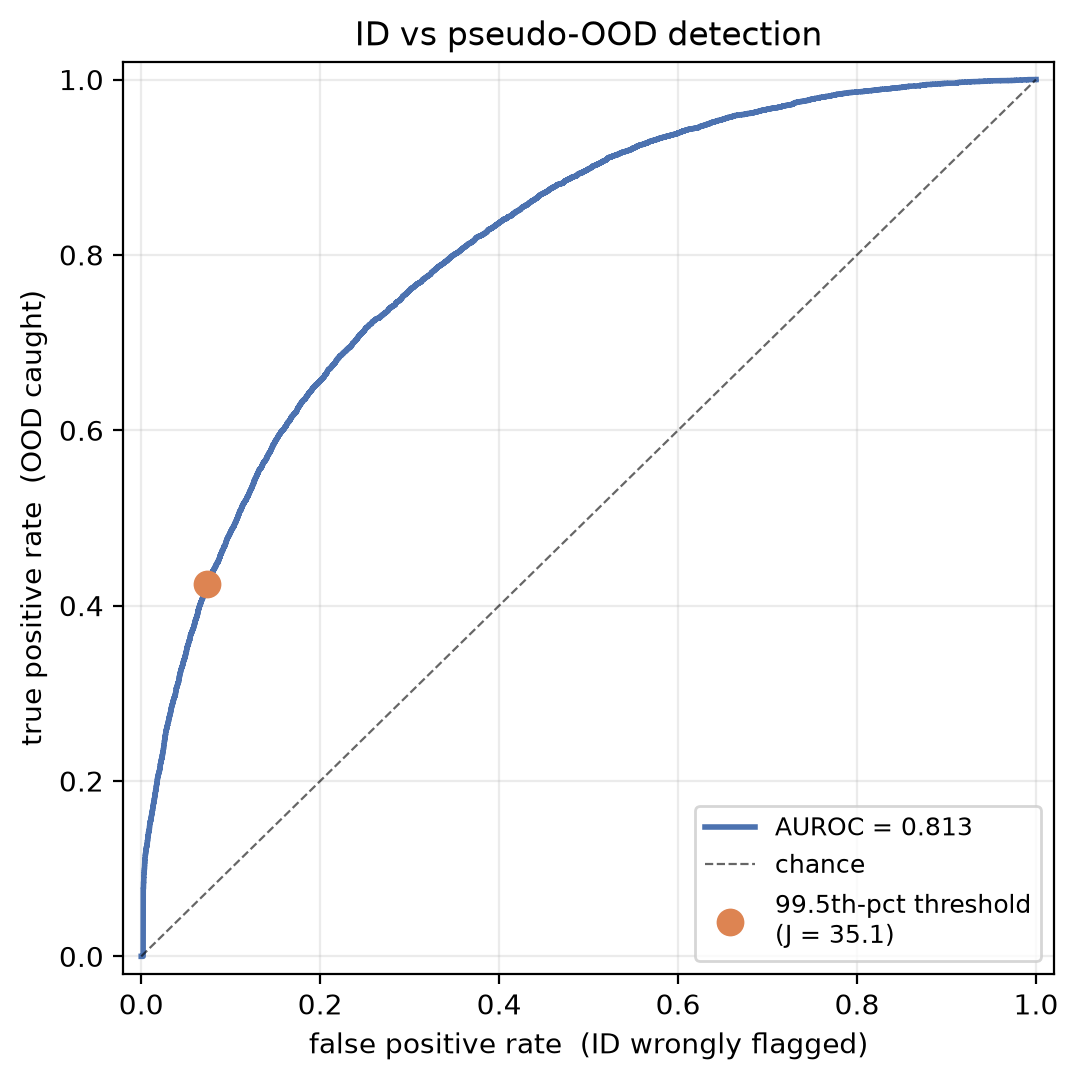

**detection_by_task.png** — Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.

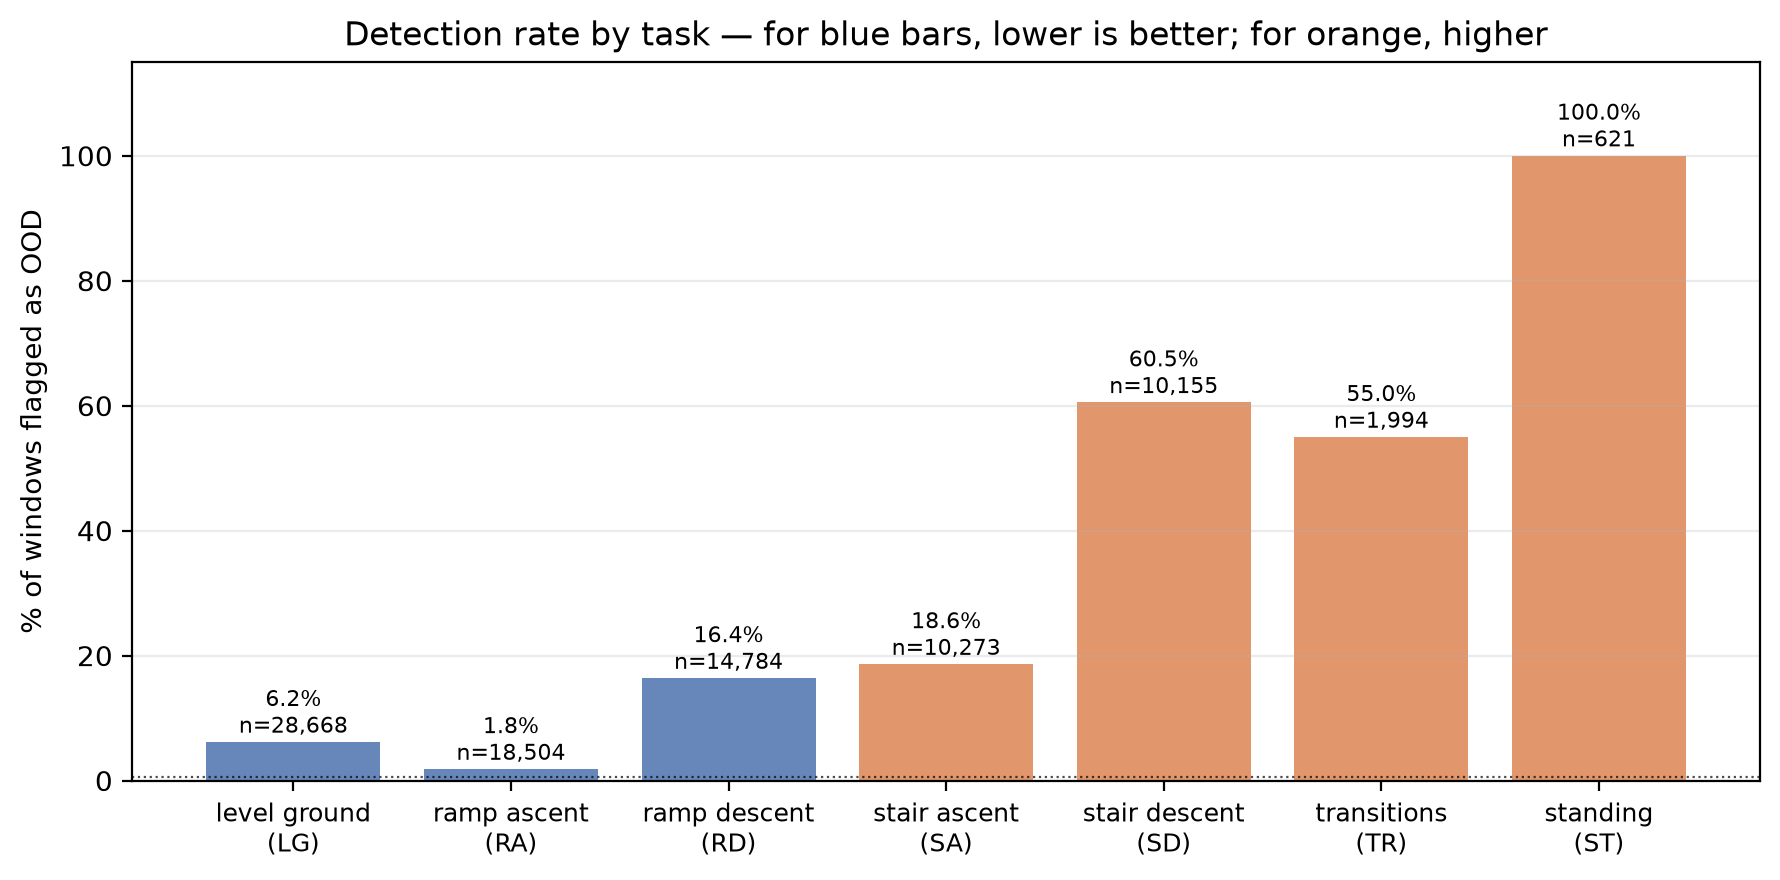

**loso.png** — Training duration selection across held-out training participants; this is LOSO, not task holdout.

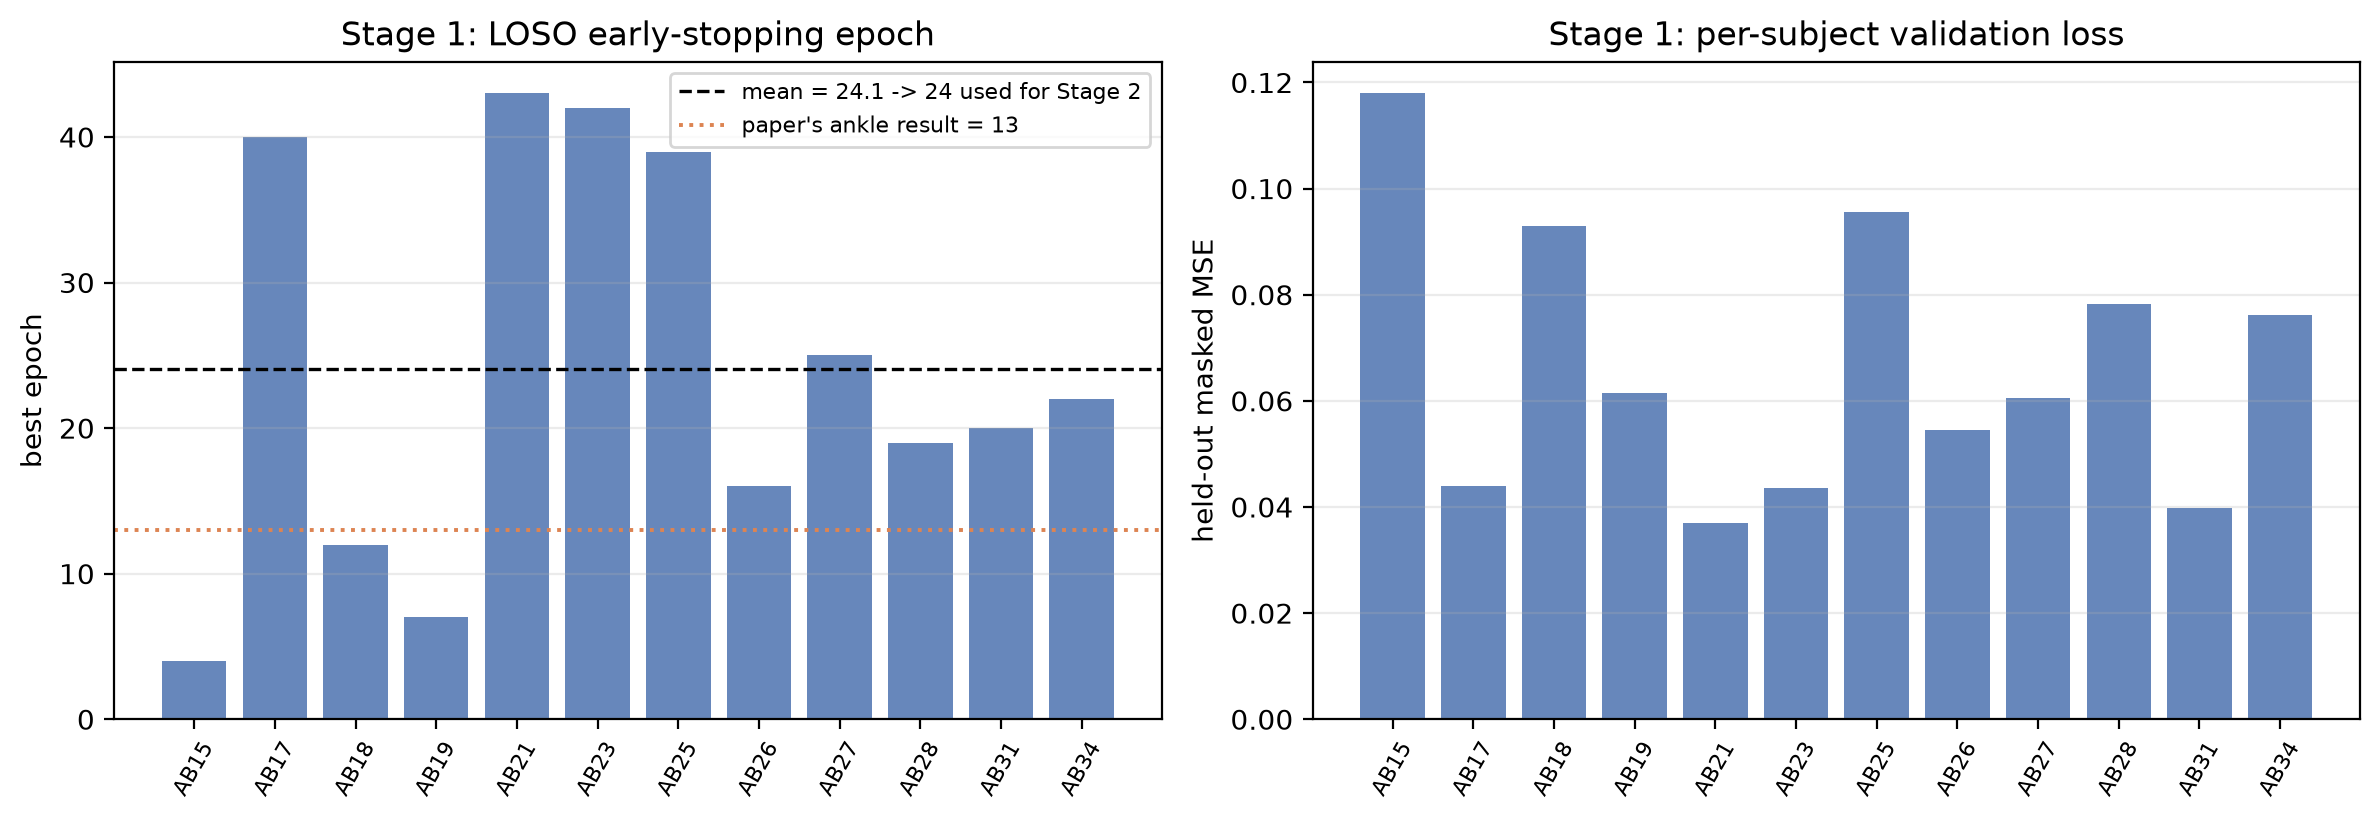

In [9]:
gallery(RUN, [('psi_by_task.png', 'Score distributions by task. The threshold is an operating point, not an ID/OOD boundary guaranteed by the model.'), ('roc.png', 'Threshold sweep: ranking quality, not the fraction detected at the saved threshold.'), ('detection_by_task.png', 'Actual flag rates at the saved training threshold; flags on ID tasks are false alarms.'), ('loso.png', 'Training duration selection across held-out training participants; this is LOSO, not task holdout.')])

## Leave-one-task-out (LOTO) stress test

SA: stair ascent; ST: standing; TR: transitions. Each run excludes the named task from **all training participants**, trains on the other six, and tests on held-out participants. This differs from LOSO epoch selection.

Standing test data come from one trial of one participant: 621 overlapping windows, or 600 for the gait-phase subset. Gait-phase LOTO uses fewer labelled windows overall. Raw window counts are not independent repetitions; cross-run changes do not isolate a causal training effect.

,held out,score,AUROC,recall (%),ID false alarms (%),J,OOD windows
0,SA,primary,0.6261,3.3096,3.5142,-0.0020,10273
1,ST,primary,0.7223,0.0000,5.4540,-0.0545,621
2,TR,primary,0.7747,46.7904,4.7371,0.4205,1994


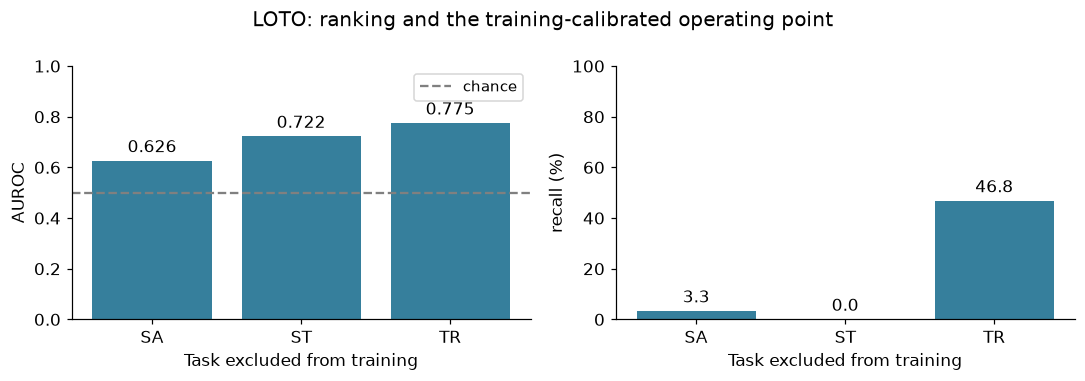

In [10]:
loto_results(KEY)

## LOTO score spread and threshold what-if

Each figure uses one separately trained holdout run: **only the named held-out task is
orange (OOD)**; the other six are blue (ID). The black dashed line is that run's saved
training threshold. Black bars span the middle 50% (IQR), with a tick at the median.
Density shapes use at most 1,500 quantile-spaced points per task; all medians, IQRs and
flag rates use **every saved test window**. Non-GAN scores use log10 axes when positive.
The plotted scores already include the original per-trial smoothing; they are not filtered again.

$$\operatorname{recall}(\tau)=\frac{\sum_{i:y_i=1}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm OOD}},
\qquad \operatorname{FPR}(\tau)=\frac{\sum_{i:y_i=0}\mathbf{1}[\widetilde\Psi_i>\tau]}{N_{\rm ID}}.$$

**Try a threshold:** replace a `None` in `LOTO_THRESHOLDS` with a numeric score threshold
(in original units, **not log10**), then rerun this cell. A purple line and exact per-task
flag rates show the what-if; `None` uses the saved threshold. The right-hand staircase
and table show recall **and ID false alarms**, not AUROC. Changing the threshold does
not change AUROC, retrain anything, or overwrite saved results.

These are **exploratory test-set what-ifs**, not validated new operating points. Choose a
final threshold using validation data, not whichever test threshold looks best. Rates
are window-weighted; overlapping windows (especially the single standing trial) are
not independent repetitions. Missing runs remain explicitly unavailable.

### Held out: SA — stair ascent

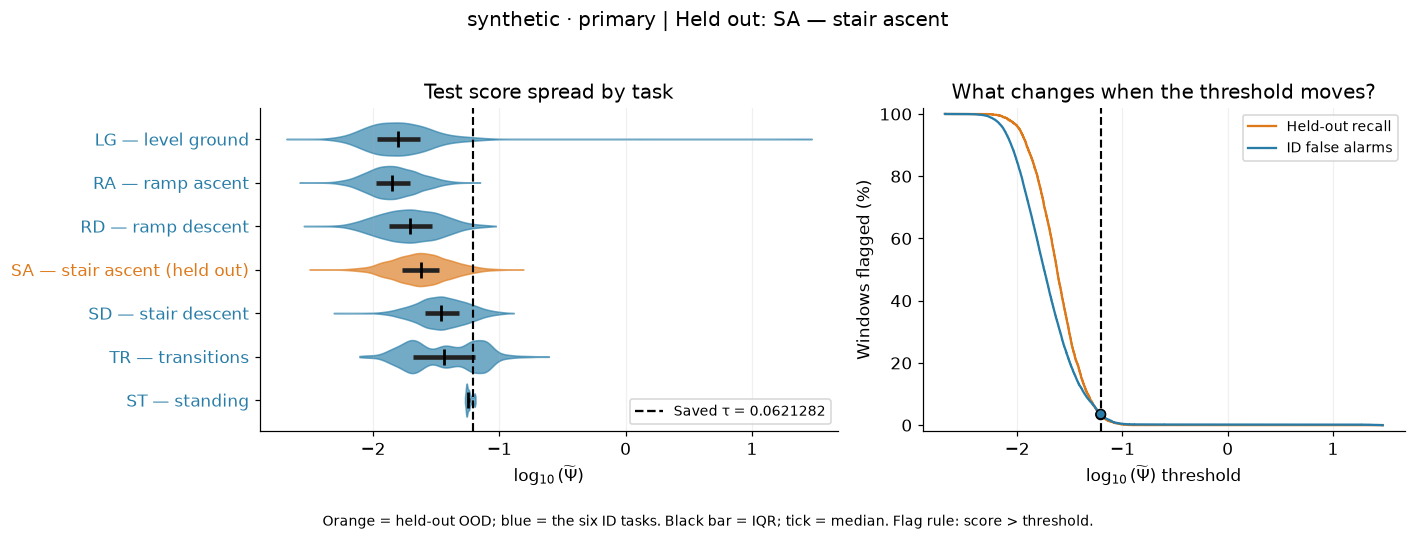

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.031064095,30.06,20.80
1,,0.046596142,10.07,8.65
2,,0.055915371,5.26,5.30
3,,0.05902178,4.16,4.23
4,,0.061506908,3.53,3.63
5,saved,0.06212819,3.31,3.51
6,,0.062749472,3.23,3.37
7,,0.065234599,2.71,2.85
8,,0.068341009,2.08,2.30
9,,0.077660237,1.17,1.43


**Per-task flags at τ = 0.06212819** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,2.23
1,RA,ID,18504,0.11
2,RD,ID,14784,1.64
3,SA,held-out OOD,10273,3.31
4,SD,ID,10155,10.69
5,TR,ID,1994,27.13
6,ST,ID,621,15.46


### Held out: ST — standing

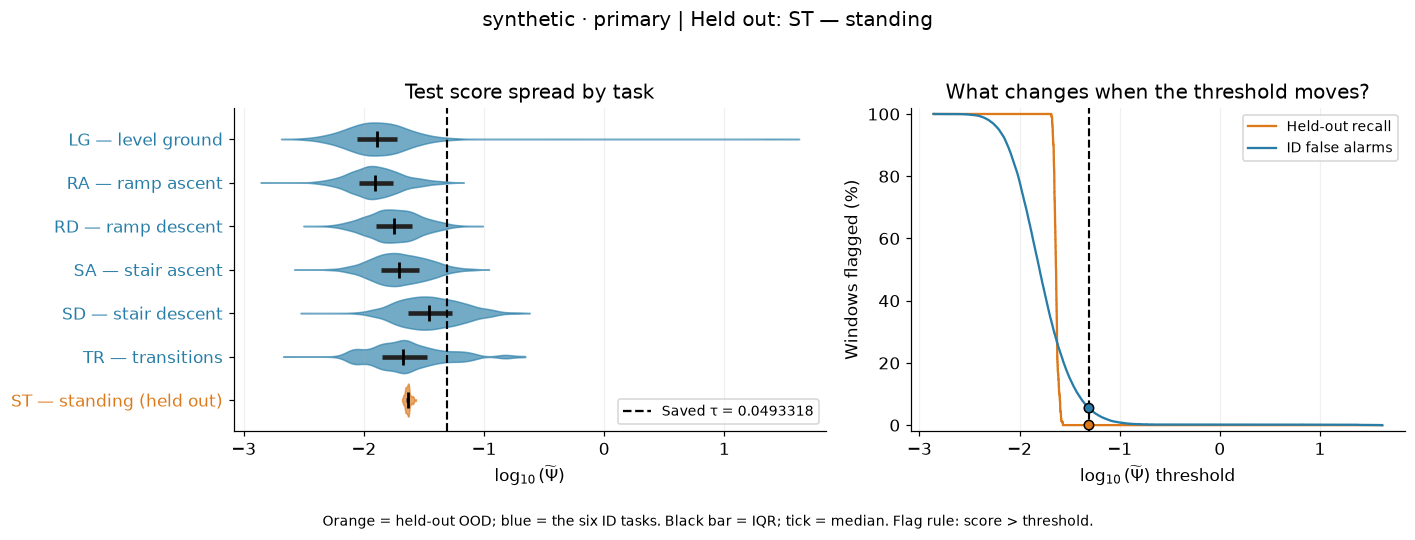

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.024665892,12.40,24.69
1,,0.036998838,0.00,10.80
2,,0.044398606,0.00,7.04
3,,0.046865195,0.00,6.17
4,,0.048838466,0.00,5.57
5,saved,0.049331784,0.00,5.45
6,,0.049825102,0.00,5.31
7,,0.051798373,0.00,4.84
8,,0.054264963,0.00,4.31
9,,0.06166473,0.00,3.08


**Per-task flags at τ = 0.049331784** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,1.60
1,RA,ID,18504,0.49
2,RD,ID,14784,1.83
3,SA,ID,10273,4.43
4,SD,ID,10155,29.93
5,TR,ID,1994,14.44
6,ST,held-out OOD,621,0.00


### Held out: TR — transitions

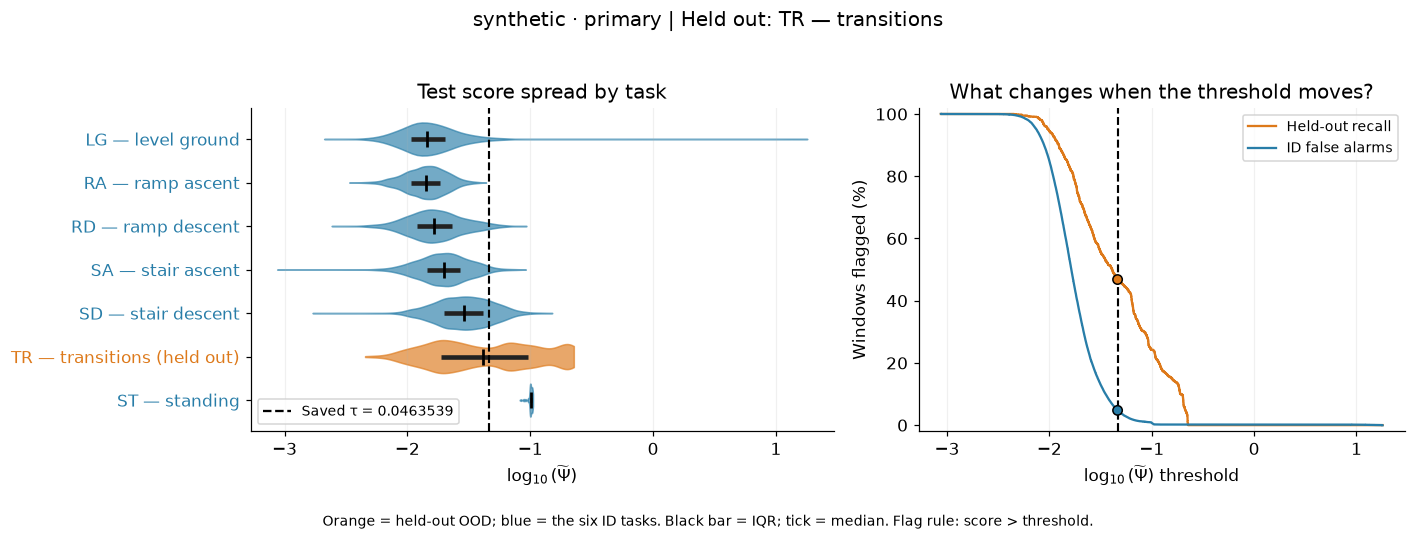

,point,threshold,OOD recall (%),ID false alarms (%)
0,,0.023176972,66.65,25.69
1,,0.034765458,53.61,10.41
2,,0.041718549,49.30,6.43
3,,0.044036246,48.09,5.50
4,,0.045890404,46.94,4.87
5,saved,0.046353944,46.79,4.74
6,,0.046817483,46.79,4.59
7,,0.048671641,46.34,4.14
8,,0.050989338,45.44,3.60
9,,0.05794243,43.63,2.52


**Per-task flags at τ = 0.046353944** (recall on the held-out task; false alarms on each ID task).

,task,role,windows,flagged (%)
0,LG,ID,28668,2.45
1,RA,ID,18504,0.00
2,RD,ID,14784,2.96
3,SA,ID,10273,2.88
4,SD,ID,10155,18.45
5,TR,held-out OOD,1994,46.79
6,ST,ID,621,100.00


In [11]:
from _loto_exploration import loto_score_explorer, threshold_rates
LOTO_THRESHOLDS = {'SA': None, 'ST': None, 'TR': None}
LOTO_SCORE = 'primary'
loto_bundles = loto_score_explorer(KEY, score=LOTO_SCORE, thresholds=LOTO_THRESHOLDS)
# Exact custom query, e.g.: threshold_rates(loto_bundles['ST'], [0.59, 0.60])

## Takeaway and next checks

The target removes the need for gait-phase labels, but can encode participant-specific sensor relationships. The useful question is whether uncertainty generalizes—not simply whether the scalar target is easy to regress.

Keep score/threshold selection on validation data. Report both ranking and recall at a declared false-alarm budget, repeat seeds, and quantify participant/trial-level variation before making robustness claims.

In [12]:
source_links(['ml/sci_rob/vanilla/targets.py', 'ml/sci_rob/vanilla/dataset.py', 'ml/sci_rob/vanilla/training/synthetic.py'])

Implementation sources: [targets.py](../../../ml/sci_rob/vanilla/targets.py), [dataset.py](../../../ml/sci_rob/vanilla/dataset.py), [synthetic.py](../../../ml/sci_rob/vanilla/training/synthetic.py)